# 06 · How much order arises by chance?

For N independent isotropic unit vectors in d dimensions, $\mathbb E\|\widehat Q\|_F^2=(1-1/d)/N$. A nonzero empirical Q therefore has a finite-sample baseline. More generally, $\mathbb E\|\widehat Q\|^2=(1-1/N)\|Q\|^2+(1-1/d)/N$ for any iid unit-direction distribution with equal weights.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [5]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

,d,N,measured,monte_carlo_se,theory
0,2,8,0.063243,0.002987,0.062500
1,2,32,0.015627,0.000789,0.015625
2,2,128,0.003997,0.000185,0.003906
3,3,8,0.085430,0.002365,0.083333
4,3,32,0.021777,0.000677,0.020833
5,3,128,0.004939,0.000165,0.005208
6,16,8,0.118246,0.000666,0.117188
7,16,32,0.029356,0.000174,0.029297
8,16,128,0.007246,0.000043,0.007324


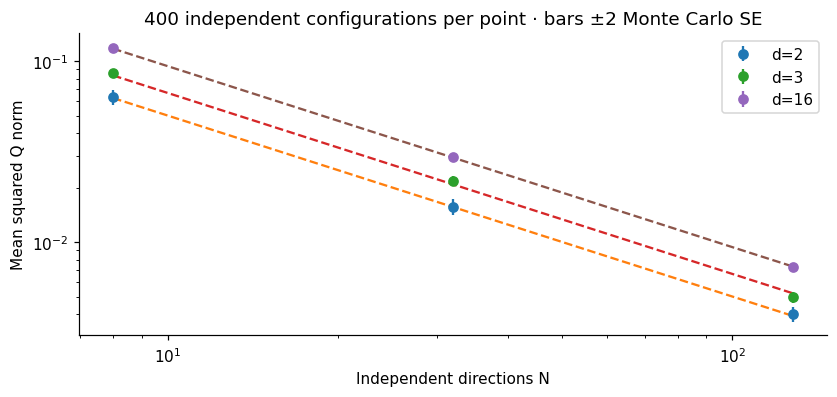

In [7]:
rng=np.random.default_rng(180)
rows=[]
for dimension in (2,3,16):
    for n in (8,32,128):
        values=[]
        for _ in range(400):
            u=rng.normal(size=(n,dimension))
            _,q=moments(u);values.append(np.sum(q*q))
        rows.append((dimension,n,np.mean(values),np.std(values,ddof=1)/20,(1-1/dimension)/n))
null=pd.DataFrame(rows,columns=['d','N','measured','monte_carlo_se','theory'])
null.to_csv(OUT/'isotropic_null.csv',index=False)
display(null.round(6))
fig,ax=plt.subplots()
for dimension,g in null.groupby('d'):
    ax.errorbar(g.N,g.measured,yerr=2*g.monte_carlo_se,fmt='o',label=f'd={dimension}')
    ax.plot(g.N,g.theory,'--')
ax.set(xscale='log',yscale='log',xlabel='Independent directions N',ylabel='Mean squared Q norm',
       title='400 independent configurations per point · bars ±2 Monte Carlo SE')
ax.legend();show('06_finite_sample_order')
assert np.max(np.abs(null.measured-null.theory)/null.monte_carlo_se)<5

## Dependence changes the effective sample size
Repeat each of eight independent directions sixteen times. The stored configuration now has 128 rows, but Q is exactly unchanged. Treating those rows as independent would assign the wrong null magnitude. Image pixels and neighboring tokens often require a dependence-aware sampling unit.

In [9]:
u=rng.normal(size=(8,3));repeated=np.repeat(u,16,axis=0)
assert np.allclose(moments(u)[1],moments(repeated)[1])
print('Squared Q before/after repetition:',np.sum(moments(u)[1]**2),np.sum(moments(repeated)[1]**2))
print('IID isotropic predictions at N=8 and N=128:',(1-1/3)/8,(1-1/3)/128)

Squared Q before/after repetition: 0.04888030873652524 0.04888030873652484
IID isotropic predictions at N=8 and N=128: 0.08333333333333334 0.005208333333333334


## Sample-size correction and its scope
For iid equal-weight directions and N > 1,
$\widehat A=\frac{N}{N-1}(\|\widehat Q\|^2-(1-1/d)/N)$
is unbiased for $\|Q\|^2$. It may be negative. Clipping creates bias. Weighted or correlated observations require a different derivation.

An anisotropic reference distribution can be estimated independently, yielding $Q_{\rm ref}=E_A[uu^T]-E_{\rm reference}[uu^T]$. The reference distribution, feature normalization and coordinate frame are part of the measurement definition. This notebook tests the isotropic equal-weight null only.